In [2]:
import urllib.request
import zipfile
import os

# Download and extract SMSSpamCollection
url = 'https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip'
zip_path = 'sms_spam_collection.zip'

print("Downloading dataset...")
urllib.request.urlretrieve(url, zip_path)

print("Extracting dataset...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('.')

# Clean up zip file
os.remove(zip_path)
print("Ready!")

Extracting dataset...
Ready!


In [4]:
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization
from sklearn.model_selection import train_test_split

# 1. Load and prepare the dataset
df = pd.read_csv('/content/SMSSpamCollection', sep='\t', header=None, names=['label', 'text'])
y = (df['label'] == 'spam').astype('int32').values
texts = df['text'].values

# 2. Vectorize texts
max_tokens, maxlen = 10000, 100
vectorize = TextVectorization(max_tokens=max_tokens, output_sequence_length=maxlen)
vectorize.adapt(texts)
X = vectorize(texts).numpy()

print("Texts vectorized successfully!")

Texts vectorized successfully!


In [5]:
# 3. Split data into train, validation, and test sets
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1111, random_state=42, stratify=y_train_val)

print(f"Train shape: {X_train.shape}")
print(f"Validation shape: {X_val.shape}")
print(f"Test shape: {X_test.shape}")

Train shape: (4456, 100)
Validation shape: (558, 100)
Test shape: (558, 100)


In [6]:
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense
from tensorflow.keras.models import Sequential

# 4. Build the Bidirectional LSTM model
model = Sequential([
    Embedding(input_dim=max_tokens, output_dim=128),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
# 5. Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=32
)

Epoch 1/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9295 - loss: 0.1988 - val_accuracy: 0.9731 - val_loss: 0.0855
Epoch 2/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9908 - loss: 0.0392 - val_accuracy: 0.9821 - val_loss: 0.0672
Epoch 3/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9957 - loss: 0.0151 - val_accuracy: 0.9803 - val_loss: 0.0800
Epoch 4/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9984 - loss: 0.0079 - val_accuracy: 0.9785 - val_loss: 0.0771
Epoch 5/5
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9993 - loss: 0.0032 - val_accuracy: 0.9839 - val_loss: 0.0769


In [8]:
# 6. Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9857 - loss: 0.0794
Test Loss: 0.0794
Test Accuracy: 0.9857


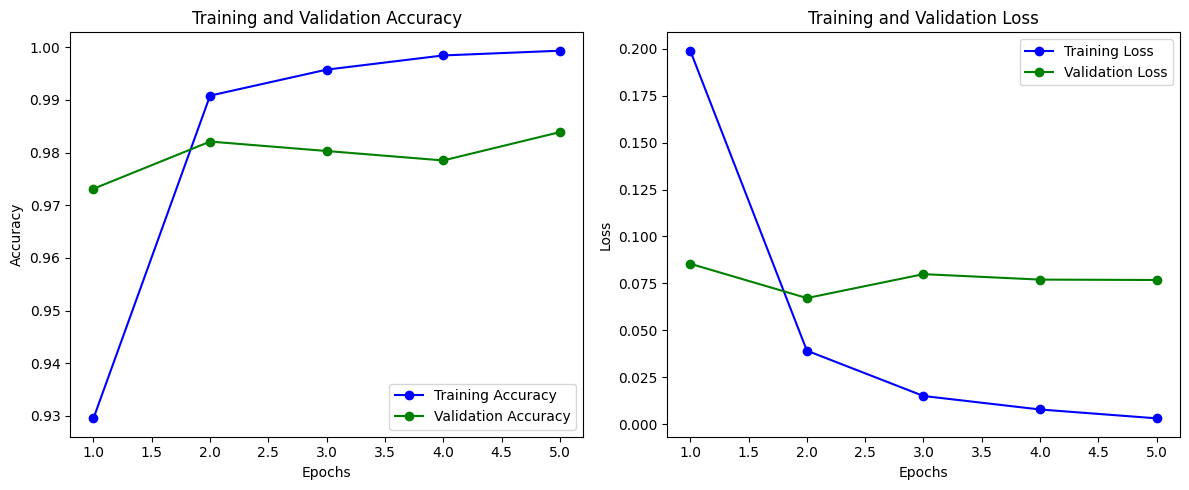

In [9]:
import matplotlib.pyplot as plt

# 7. Plot training & validation accuracy and loss curves
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss_curve = history.history['loss']
val_loss_curve = history.history['val_loss']
epochs = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'bo-', label='Training Accuracy')
plt.plot(epochs, val_acc, 'go-', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs, loss_curve, 'bo-', label='Training Loss')
plt.plot(epochs, val_loss_curve, 'go-', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step
Classification Report:

              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       483
        Spam       0.97      0.92      0.95        75

    accuracy                           0.99       558
   macro avg       0.98      0.96      0.97       558
weighted avg       0.99      0.99      0.99       558



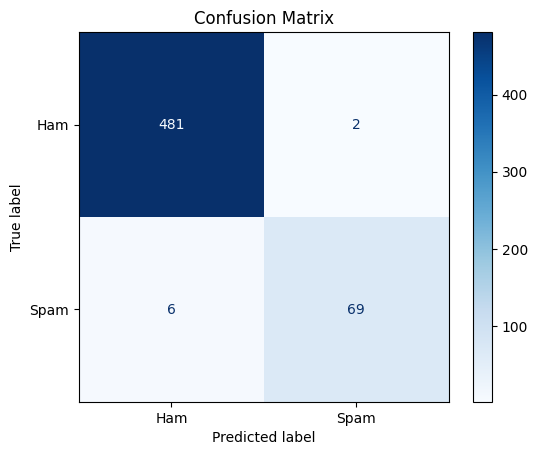

In [10]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 8. Predict on test set and plot metrics
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype('int32')

# Print classification report showing Precision, Recall, and F1-Score
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))

# Compute and plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ham', 'Spam'])
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

In [11]:
# 9. Showcase 5 sample predictions on actual text samples from the test split
# Find indices in the test split
test_indices = df.index[-len(X_test):] # Map the last test split back to text
sample_indices = [10, 50, 100, 150, 200]

print("--- 5 Sample Predictions ---\n")
for idx in sample_indices:
    text_sample = df.iloc[test_indices[idx]]['text']
    true_label = df.iloc[test_indices[idx]]['label']
    pred_prob = y_pred_prob[idx][0]
    predicted_label = 'spam' if pred_prob > 0.5 else 'ham'

    print(f"Text: {text_sample}")
    print(f"True Label: {true_label} | Predicted Label: {predicted_label} (Confidence: {pred_prob:.4f})")
    print("-" * 50)

--- 5 Sample Predictions ---

Text: Anyway holla at me whenever you're around because I need an excuse to go creep on people in sarasota
True Label: ham | Predicted Label: ham (Confidence: 0.0003)
--------------------------------------------------
Text: Ok i also wan 2 watch e 9 pm show...
True Label: ham | Predicted Label: ham (Confidence: 0.0001)
--------------------------------------------------
Text: Argh why the fuck is nobody in town ;_;
True Label: ham | Predicted Label: ham (Confidence: 0.0007)
--------------------------------------------------
Text: Congrats 2 mobile 3G Videophones R yours. call 09063458130 now! videochat wid ur mates, play java games, Dload polypH music, noline rentl. bx420. ip4. 5we. 150p
True Label: spam | Predicted Label: ham (Confidence: 0.0003)
--------------------------------------------------
Text: Natalja (25/F) is inviting you to be her friend. Reply YES-440 or NO-440 See her: www.SMS.ac/u/nat27081980 STOP? Send STOP FRND to 62468
True Label: spam | 

### 10. Summary Report

#### (a) Why padding is needed
Text sequences vary in length. Deep Learning models require a uniform batch shape to perform parallel tensor computations on GPUs. Padding standardizes sequence length by appending zeros to shorter sequences or truncating longer ones.

#### (b) Why embeddings beat one-hot representations
One-hot vectors are sparse, high-dimensional, and completely blind to semantic relationships between words. Word Embeddings represent words in dense vector spaces where semantically similar words are mapped close together, capturing deep context.

#### (c) Why Bidirectional networks help here
Standard RNNs process texts left-to-right. Bidirectional models process text in both forward and backward directions, capturing context from both past and future words simultaneously (e.g., catching "call now to win" with context clues at both ends of the sentence).

#### (d) Output-layer / Loss choice
For binary classification (spam vs. ham), we use a single unit with a **Sigmoid** activation function to output probabilities between `[0, 1]`, optimized using the **Binary Crossentropy** loss function.

#### (e) Why accuracy is misleading on imbalanced data and alternative metrics
Spam datasets are highly imbalanced (mostly ham). A lazy model predicting "ham" for everything can still achieve 87%+ accuracy while failing completely to catch spam. We use **Precision, Recall, F1-Score**, and a **Confusion Matrix** to track true spam detection capability.